<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/DLens_02_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
path = "/content/drive/MyDrive/DemandLens/Data/"
RAW  = path + "preprocessed/"

cal    = pd.read_csv(RAW + "calendar.csv")
prices = pd.read_csv(RAW + "sell_prices.csv")
sales  = pd.read_csv(RAW + "sales_train_evaluation.csv")

In [ ]:
cal.shape, prices.shape, sales.shape

((1969, 14), (6841121, 4), (30490, 1947))

In [ ]:
cal.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [ ]:
prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [ ]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


In [ ]:
import os, gc

# ---------- SETTINGS (change only here) ----------
STORES = ["CA_1"]                # one store
# STORES = ["CA_1", "CA_2", "CA_3", "CA_4"]      # whole California
# STORES = sorted(sales["store_id"].unique())    # all 10 stores

CATEGORIES = None                # None = all categories
# CATEGORIES = ["FOODS"]         # only FOODS

OUT = path + "processed/"        # folder where the clean files are saved
os.makedirs(OUT, exist_ok=True)

# ---------- CALENDAR (done once) ----------
cal["date"] = pd.to_datetime(cal["date"])     # text to real date
cal1 = cal.iloc[:1941].copy()                 # keep only the 1941 days that have sales

day_cols = [c for c in sales.columns if c.startswith("d_")]   # list of d_1 ... d_1941
len(day_cols)                                 # should be 1941

1941

In [ ]:
def prepare_store(store):
    """Make one clean, ready-to-use file for one store."""

    out_file = OUT + store + "_clean.parquet"
    if os.path.exists(out_file):              # if an old file exists, delete it and rebuild
        os.remove(out_file)
        print(store, "old file deleted, building again")

    # 1. Keep only this store (and only the chosen categories)
    sub = sales[sales["store_id"] == store].copy()
    if CATEGORIES is not None:
        sub = sub[sub["cat_id"].isin(CATEGORIES)].copy()
    sub[day_cols] = sub[day_cols].astype("int16")    # smaller numbers = less RAM

    # 2. Melt: from one row per item to one row per item per day
    df = sub.melt(id_vars=["item_id", "dept_id", "cat_id", "store_id"],
                  value_vars=day_cols, var_name="d", value_name="sales")
    n_melt = len(df)
    del sub

    # 3. Add calendar data (date, month, event, snap) using the day label "d"
    state = store.split("_")[0]                      # "CA_1" becomes "CA"
    c = cal1[["d", "date", "wm_yr_wk", "wday", "month", "year",
              "event_name_1", "event_type_1"]].copy()
    c["snap"] = cal1["snap_" + state].values         # snap column of this store's state
    df = df.merge(c, on="d", how="left")
    assert len(df) == n_melt, "Calendar merge changed the number of rows"

    # 4. Add price using store, item and week
    p = prices[prices["store_id"] == store][["store_id", "item_id", "wm_yr_wk", "sell_price"]]
    df = df.merge(p, on=["store_id", "item_id", "wm_yr_wk"], how="left")
    assert len(df) == n_melt, "Price merge changed the number of rows"
    n_missing_price = int(df["sell_price"].isna().sum())

    # 5. Remove the rows before each item's first sale
    #    (before that, the item was not on sale yet, so sales = 0 is not real demand)
    df["first_date"] = (df["date"].where(df["sales"] > 0)
                        .groupby([df["store_id"], df["item_id"]], observed=True)
                        .transform("min"))
    df = df[df["date"] >= df["first_date"]].drop(columns=["first_date", "d", "wm_yr_wk"])

    # 6. Save memory, sort by item and date, and save the file
    df["sell_price"] = df["sell_price"].astype("float32")
    for col in ["item_id", "dept_id", "cat_id", "store_id", "event_name_1", "event_type_1"]:
        df[col] = df[col].astype("category")
    df = df.sort_values(["item_id", "date"]).reset_index(drop=True)
    df.to_parquet(out_file)

    print(store, "| after melt:", n_melt,
          "| missing price before cleaning:", n_missing_price,
          "| rows removed:", n_melt - len(df),
          "| final rows:", len(df),
          "| missing price left:", int(df["sell_price"].isna().sum()))
    del df, p, c
    gc.collect()

In [ ]:
for s in STORES:
    prepare_store(s)

CA_1 old file deleted, building again
CA_1 | after melt: 5918109 | missing price before cleaning: 1129842 | rows removed: 1136545 | final rows: 4781564 | missing price left: 0


## Data Preparation: What we did and what we found

### What we did
1. We kept only one store (CA_1) first, and then melted the table. Melting all 10 stores at once would use too much RAM.
2. Melt changed the table from "one row per item" to "one row per item per day". After the melt we have 5,918,109 rows.
3. We joined the calendar (date, month, event, SNAP) using the day label, and the price using store, item and week. The number of rows did not change after both joins, so the joins are correct.
4. We removed the rows before each item's first sale, and kept the rest in date order.
5. The code is one function that works for any store. To use more stores, we only change the STORES list.

### What we found
1. After the joins, 1,129,842 rows (19.1%) have no sell_price.
2. All of these missing prices are before the item's first sale. After the first sale, no price is missing.
3. This means the item was not on sale yet in those weeks (there is no price row for it in the price file).
4. 1,136,545 rows are before an item's first sale. About 6,703 of them have a price but no sales.

### Decision
We remove all rows before each item's first sale. Before that day the item was not on sale, so the zero sales are not real demand, and keeping them would teach the model wrong patterns. This also removes all the missing prices. After cleaning we have 4,781,564 rows and no missing price.

### Still to do
1. Remove the 5 Christmas days after we create the lag features, so the lags stay correct.

In [ ]:
df = pd.read_parquet(OUT + "CA_1_clean.parquet")

In [ ]:
df.sample(5)

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,event_type_1,snap,sell_price
2207400,FOODS_3_795,FOODS_3,FOODS,CA_1,9,2015-09-27,2,9,2015,NaN,NaN,0,2.98
4411342,HOUSEHOLD_2_288,HOUSEHOLD_2,HOUSEHOLD,CA_1,0,2013-10-02,5,10,2013,NaN,NaN,1,3.97
702834,FOODS_2_224,FOODS_2,FOODS,CA_1,0,2015-02-11,5,2,2015,NaN,NaN,0,4.96
3086959,HOBBIES_2_113,HOBBIES_2,HOBBIES,CA_1,0,2012-09-17,3,9,2012,NaN,NaN,0,5.77
1822853,FOODS_3_543,FOODS_3,FOODS,CA_1,0,2012-10-29,3,10,2012,NaN,NaN,0,3.78


In [ ]:
df.isna().sum()

,0
item_id,0
dept_id,0
cat_id,0
store_id,0
sales,0
date,0
wday,0
month,0
year,0
event_name_1,4393222


In [ ]:
df.shape

(4781564, 13)

In [ ]:
df.duplicated(subset=["item_id", "date"]).sum()

np.int64(0)

In [ ]:
pd.options.display.float_format = '{:,.2f}'.format
df["sell_price"].describe()

,sell_price
count,"4,781,564.00"
mean,4.41
std,3.39
min,0.01
25%,2.22
50%,3.47
75%,5.77
max,30.98


In [ ]:
df["date"].min(), df["date"].max()

(Timestamp('2011-01-29 00:00:00'), Timestamp('2016-05-22 00:00:00'))

In [ ]:
df["item_id"].nunique()

3049

In [ ]:
print("Percentage of 0s in Sales : ",(df["sales"] == 0).mean() * 100)

Percentage of 0s in Sales :  55.14482290731652


/tmp/ipykernel_600/1444342326.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("dept_id")["sales"].sum().plot(kind="bar")


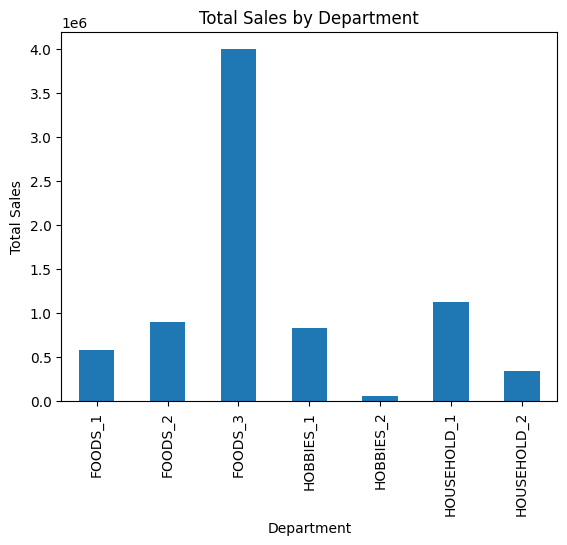

In [ ]:
df.groupby("dept_id")["sales"].sum().plot(kind="bar")

plt.title("Total Sales by Department")
plt.xlabel("Department")
plt.ylabel("Total Sales")
plt.show()

## Final Observations and Conclusion

### What the final data looks like
1. The final table has 4,781,564 rows and 13 columns. It covers 3,049 items in store CA_1, from 2011-01-29 to 2016-05-22.
2. There are no duplicate rows and no missing sell_price.
3. The only empty values are in event_name_1 and event_type_1 (4,393,222 rows, about 91.9%). Empty means there is no event on that day, so it is not missing data.
4. About 55.1% of the item-days have zero sales, even after removing the rows before each item's first sale. So zero sales are very common.
5. The department with the most sales is FOODS_3 (about 4 million units). The one with the least is HOBBIES_2.
6. The sell_price goes from 0.01 to 30.98 dollars in this store.

### Conclusion
1. The data is clean and ready for feature engineering. The clean table is saved as CA_1_clean.parquet.
2. Because more than half of the days have zero sales, MAPE is not reliable. We use WAPE as the main metric, with MAE and RMSE.
3. The code is one function. To use more stores later, we only change the STORES list.